In [ ]:
# Monte Carlo Simulation
# EU ETS, EUA Stochastic Policy-Driven Annual Price Dynamics Scenarios

import numpy as np
import pandas as pd
from IPython.display import display

# Load historical data
df = pd.read_excel("Dynamic_Carbon_Exposure_Model.xlsx", sheet_name="EUA_Historical_Prices")

prices = df["EUA"].values.astype(float)   # 2005–2025 EUA prices
log_returns = np.log(prices[1:] / prices[:-1])

mu_hist = log_returns.mean()
sigma_hist = log_returns.std()

# Policy regimes (baseline assumptions)
mu_regimes = {
    "status_quo": 0.03,     # weak policy tightening (3% yearly EUA-price increase)
    "fit_for_55": 0.06,     # EU target-aligned (6% yearly EUA-price increase)
    "accelerated": 0.10    # aggressive decarbonisation (10% yearly EUA-price increase)
}

# Simulation parameters
S0 = prices[-1]     # last observed EUA price (2025)
T = 10              # forecast horizon (years)
n_sims = 1000000          # number of simulation paths

np.random.seed(42)

# Monte Carlo GBM
def simulate_ets_prices(S0, mu, sigma, T, n_sims):
    paths = np.zeros((n_sims, T))
    paths[:, 0] = S0            # 2025

    for t in range(1, T):
        z = np.random.normal(size=n_sims)
        paths[:, t] = paths[:, t-1] * np.exp(
            (mu - 0.5 * sigma**2) + sigma * z
        )
    return paths

# Run simulations
sigma = 0.25  # POLICY volatility, not historical

results = {}

for regime, mu in mu_regimes.items():
    results[regime] = simulate_ets_prices(
        S0, mu, sigma, T, n_sims
    )

# Risk Metrics & Uncertainty Range
summary = {}

for regime, paths in results.items():
    summary[regime] = {
        "mean": paths.mean(axis=0),
        "p25": np.percentile(paths, 25, axis=0),       # Change Uncertainity Range How you see fit
        "p50": np.percentile(paths, 50, axis=0),       # eg.: p25-p75 ; p10-p90
        "p75": np.percentile(paths, 75, axis=0)
    }

# Time logic
start_year = int(df["Year"].iloc[-1]) + 1
years = list(range(start_year, start_year + T))

# Output Table
tables = {}

for regime, stats in summary.items():
    tables[regime] = pd.DataFrame({
        "Year": np.array(years),
        #"Mean": np.array(stats["mean"]),
        "P25": np.array(stats["p25"]),
        "P50": np.array(stats["p50"]),
        "P75": np.array(stats["p75"])
    })

# Display full tables
pd.set_option("display.max_rows", None)

for regime, table in tables.items():
    print("\n" + "=" * 45)
    print(f"REGIME: {regime.upper()}")
    print("=" * 45)
    display(table.round(2).style.hide(axis="index"))



REGIME: STATUS_QUO


Year,P25,P50,P75
2026,70.370000,70.370000,70.370000
2027,59.340000,70.260000,83.170000
2028,55.260000,70.150000,89.090000
2029,52.310000,70.020000,93.900000
2030,49.950000,70.000000,98.050000
2031,47.950000,69.970000,101.940000
2032,46.180000,69.820000,105.480000
2033,44.650000,69.700000,109.050000
2034,43.270000,69.620000,112.260000
2035,41.960000,69.570000,115.530000



REGIME: FIT_FOR_55


Year,P25,P50,P75
2026,70.370000,70.370000,70.370000
2027,61.190000,72.430000,85.700000
2028,58.690000,74.540000,94.580000
2029,57.250000,76.650000,102.630000
2030,56.320000,78.940000,110.540000
2031,55.690000,81.210000,118.420000
2032,55.330000,83.610000,126.430000
2033,55.080000,86.090000,134.410000
2034,54.990000,88.650000,142.720000
2035,55.000000,91.190000,151.220000



REGIME: ACCELERATED


Year,P25,P50,P75
2026,70.370000,70.370000,70.370000
2027,63.690000,75.400000,89.250000
2028,63.620000,80.740000,102.460000
2029,64.570000,86.540000,115.900000
2030,66.100000,92.660000,129.800000
2031,68.060000,99.270000,144.670000
2032,70.280000,106.300000,160.680000
2033,72.900000,113.750000,177.870000
2034,75.680000,121.870000,196.450000
2035,78.730000,130.530000,216.540000


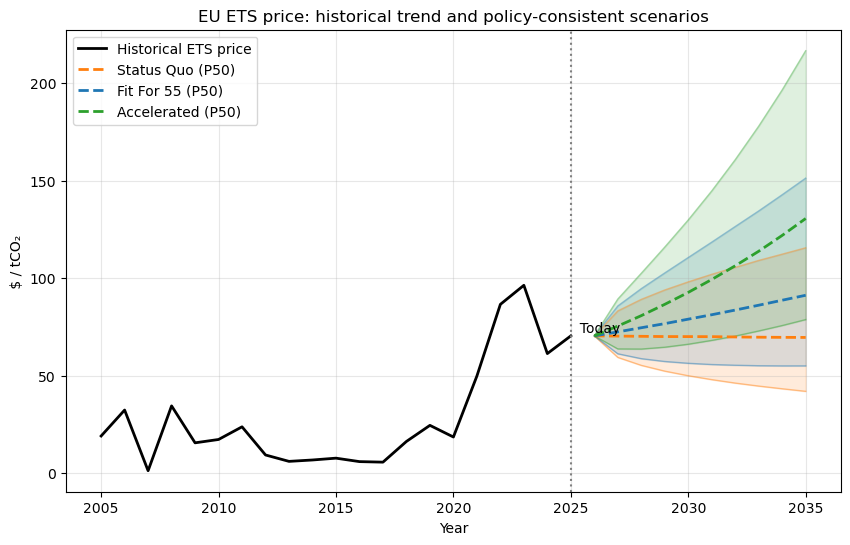

In [ ]:
import matplotlib.pyplot as plt

years_hist = df["Year"]
prices_hist = df["EUA"]

years_future = list(range(years_hist.iloc[-1] + 1, years_hist.iloc[-1] + T + 1))

colors = {
    "status_quo": "tab:orange",
    "fit_for_55": "tab:blue",
    "accelerated": "tab:green"
}

plt.figure(figsize=(10, 6))

# Historical
plt.plot(
    years_hist,
    prices_hist,
    color="black",
    linewidth=2,
    label="Historical ETS price"
)

# Scenarios
for i, (regime, table) in enumerate(tables.items()):
    color = colors[regime]

    # Median line
    plt.plot(
        years_future,
        table["P50"],
        linestyle="--",
        color=color,
        linewidth=2,
        label=f"{regime.replace('_', ' ').title()} (P50)",
        zorder=3
    )

    # Uncertainty fan 
    plt.fill_between(
        years_future,
        table["P25"],
        table["P75"],
        color=color,
        alpha=0.15,
        zorder=1
    )

    # Explicit P25 / P75 edges
    plt.plot(
        years_future,
        table["P25"],
        color=color,
        alpha=0.4,
        linewidth=1,
        zorder=2
    )
    plt.plot(
        years_future,
        table["P75"],
        color=color,
        alpha=0.4,
        linewidth=1,
        zorder=2
    )
# Vertical line at today
plt.axvline(x=years_hist.iloc[-1], linestyle=":", color="grey")
plt.text(years_hist.iloc[-1], prices_hist.iloc[-1], "  Today", va="bottom")

plt.xlabel("Year")
plt.ylabel(" $ / tCO₂ ")
plt.title("EU ETS price: historical trend and policy-consistent scenarios")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [3]:
# Export MC outputs to Excel (single backend sheet)

output_file = r"C:\Users\POU\OneDrive - Avertim\DynamicModel\Dynamic_Carbon_Exposure_Model.xlsx"

export_frames = []

for regime, table in tables.items():
    tmp = table.copy()
    tmp["Regime"] = regime
    export_frames.append(tmp)

mc_sim_out = pd.concat(export_frames, ignore_index=True)

with pd.ExcelWriter(
    output_file,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:
    mc_sim_out.round(2).to_excel(
        writer,
        sheet_name="MC_SIM_OUT",
        index=False
    )

print("MC simulation outputs written to sheet: MC_SIM_OUT")

MC simulation outputs written to sheet: MC_SIM_OUT


In [4]:
# Export to PowerBI

rows = []

for regime, table in tables.items():
    for _, row in table.iterrows():
        rows.append({
            "Year": int(row["Year"]),
            "Regime": regime,
            "P25": row["P25"],
            "P50": row["P50"],
            "P75": row["P75"]
        })

df_scenarios = pd.DataFrame(rows)

df_long = df_scenarios.melt(
    id_vars=["Year", "Regime"],
    value_vars=["P25", "P50", "P75"],
    var_name="Percentile",
    value_name="EUA_Price"
)

df_hist = pd.DataFrame({
    "Year": years_hist,
    "Regime": "historical",
    "Percentile": "Observed",
    "EUA_Price": prices_hist
})

output_path = r"C:\Users\POU\OneDrive - Avertim\PowerBI_Data"

df_out = pd.concat([df_hist, df_long], ignore_index=True)

df_out.to_excel(
    f"{output_path}\\EUA_price_scenarios_for_PowerBI.xlsx",
    index=False
)


In [5]:
print(sigma_hist)

1.1523280031145642
